In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
cmap2 = plt.cm.twilight
rng = np.random.default_rng(seed=12345)   # PCG64 by default
cm = 1 / 2.54

# Hippocampal Data

### Load data


In [9]:
n_channels = 31
fs = 1250 # Hz

path = '../Hippocampal/data/'
file = 'ec013.527.eeg'
x = np.fromfile(path+file, dtype=np.int16)
x = x.reshape(-1, n_channels)

signal = x[:,5]      # sixth channel
time = np.arange(len(signal))/fs
print(time.shape[0])

1325125


### Plot dense data

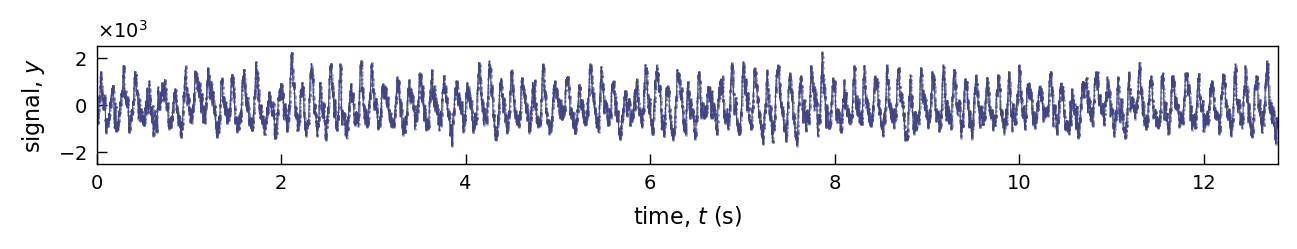

In [8]:
imin = 10000
istep = 1
Nmax = 16000
imax = imin + istep*Nmax

tk = time[imin:imax:istep] - time[imin]
yk = signal[imin:imax:istep]
dtmin = np.diff(tk).mean()

# fixed axis geometry
ax_h = 1.5 * cm
ax_w = 15 * cm

left = 1.5 * cm
bottom = 1.5 * cm
right = 0.5 * cm
top = 0.5 * cm

fig_w = left + ax_w + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))

ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h
])

ax.plot(tk, yk,  '-', c=cmap(0.2), lw=0.4)
ax.plot(tk, yk,  '.', alpha=0.5, c=cmap(0.2), mew=0, ms=2)
ax.set_xlim(tk[0], tk[-1])
ax.set_ylim(-2500, 2500)
ax.yaxis.set_major_formatter(formatter)
ax.yaxis.get_offset_text().set_fontsize(7)

ax.set_xlabel('time, $t$ (s)', fontsize=8)
ax.set_ylabel('signal, $y$', fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/HippocampalTrace.pdf')

# FFT Analysis

Subtract the sample mean to remove the zero-frequency offset, then compute the one-sided FFT and its power spectral density.

In [10]:
centered_signal = yk.astype(float) - yk.mean()
sampling_frequency = 1 / dtmin
fft_values = np.fft.rfft(centered_signal)
frequencies = np.fft.rfftfreq(centered_signal.size, d=dtmin)

# One-sided power spectral density (signal units squared per Hz).
power_spectrum = np.abs(fft_values) ** 2 / (sampling_frequency * centered_signal.size)
power_spectrum[1:-1] *= 2

peak_index = 1 + np.argmax(power_spectrum[1:])
peak_frequency = frequencies[peak_index]
print(f'Dominant nonzero frequency: {peak_frequency:.3f} Hz')

Dominant nonzero frequency: 8.359 Hz


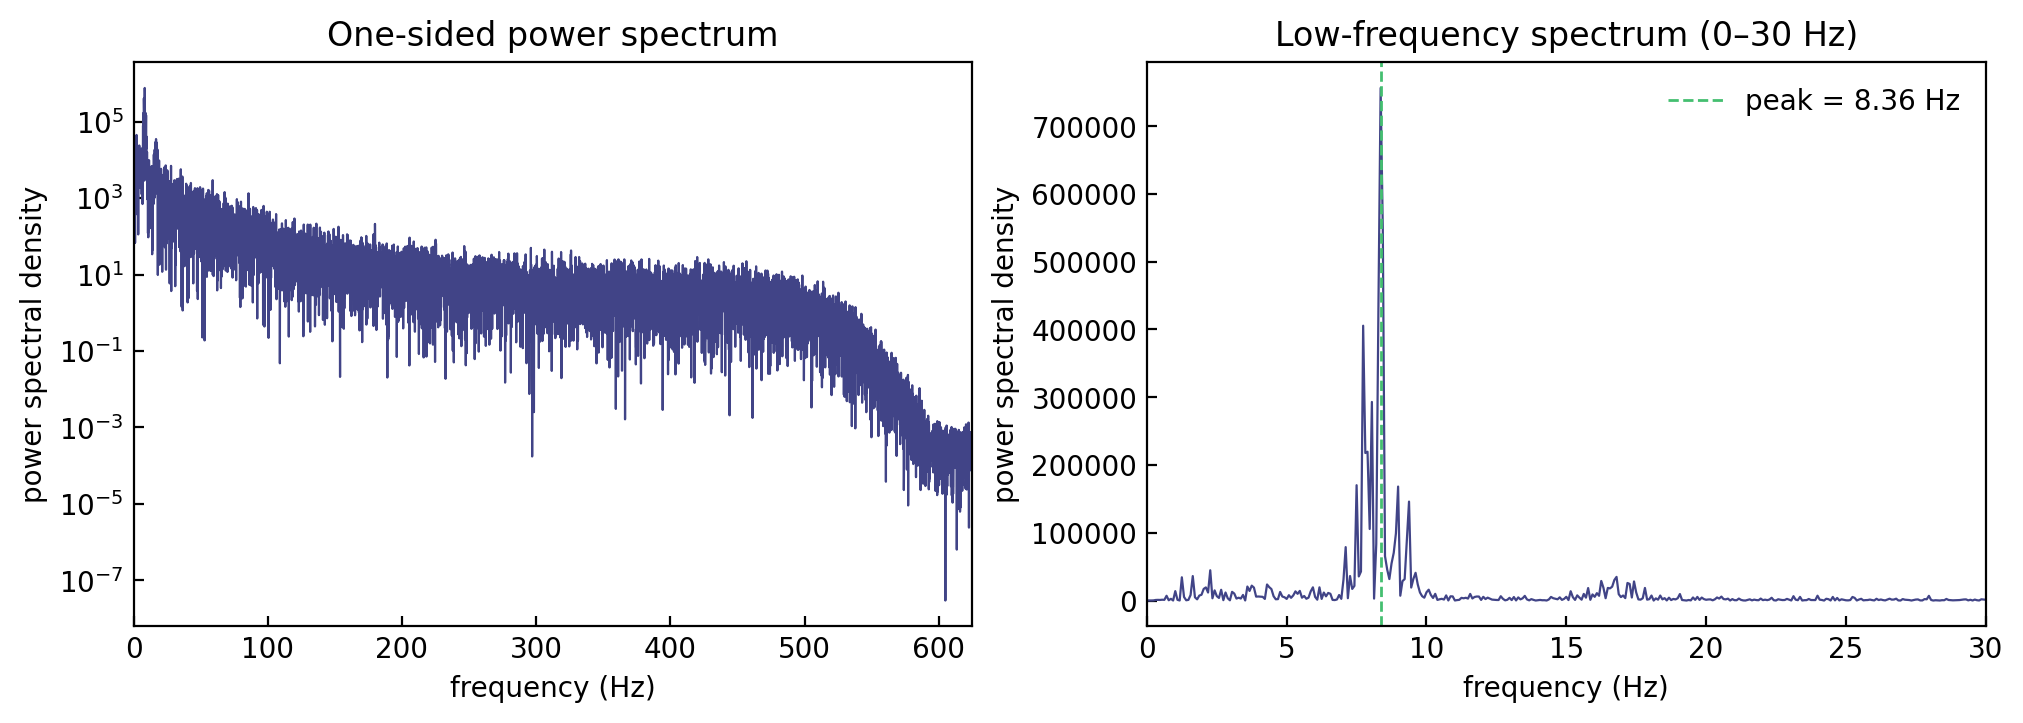

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)

axes[0].semilogy(frequencies[1:], power_spectrum[1:], color=cmap(0.2), lw=0.8)
axes[0].set(
    xlabel='frequency (Hz)',
    ylabel='power spectral density',
    title='One-sided power spectrum',
    xlim=(0, sampling_frequency / 2),
)

max_frequency = 30.0
frequency_mask = (frequencies > 0) & (frequencies <= max_frequency)
axes[1].plot(
    frequencies[frequency_mask],
    power_spectrum[frequency_mask],
    color=cmap(0.2),
    lw=0.8,
)
axes[1].axvline(
    peak_frequency,
    color=cmap(0.7),
    ls='--',
    lw=1,
    label=f'peak = {peak_frequency:.2f} Hz',
)
axes[1].set(
    xlabel='frequency (Hz)',
    ylabel='power spectral density',
    title=f'Low-frequency spectrum (0–{max_frequency:g} Hz)',
    xlim=(0, max_frequency),
)
axes[1].legend(frameon=False)

for ax in axes:
    ax.tick_params(direction='in')

plt.show()

## Harmonic fit